In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
TASK = Path.cwd().parent
ROOT = TASK.parent
INPUT, OUTPUT = TASK / 'input', TASK / 'output'
CONFIG = json.loads((ROOT / 'config.json').read_text())
EPS, Y, SEED = CONFIG['eps'], CONFIG['last_year'], CONFIG['seed']

In [ ]:
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
ORDER = ['empirical_complete'] + CONFIG['models']
PALETTE = dict(zip(ORDER,sns.color_palette('colorblind',len(ORDER))))
DASHES = dict(zip(ORDER, ['', (4,2), (1,1), (6,2,1,2), (3,1,1,1), (8,2)]))
MARKERS = dict(zip(ORDER,['o','s','^','D','v','P']))
def save(fig,name):
    fig.tight_layout()
    fig.savefig(OUTPUT / (name+'.png'),dpi=180,bbox_inches='tight')
    fig.savefig(OUTPUT / (name+'.pdf'),bbox_inches='tight')
    plt.show()
    plt.close(fig)
def lines(data,x,y,ax):
    sns.lineplot(data=data,x=x,y=y,hue='source',style='source',hue_order=ORDER,style_order=ORDER,
                 palette=PALETTE,dashes=DASHES,markers=MARKERS,markersize=3,ax=ax)

In [4]:
moments = pd.read_csv(INPUT / 'annual_moments.csv')
ranks = pd.read_csv(INPUT / 'rank_correlations.csv')
qq = pd.read_csv(INPUT / 'qq_points.csv')
hazard = pd.read_csv(INPUT / 'restart_hazard.csv')
maximum = pd.read_csv(INPUT / 'year_of_maximum.csv')
params = pd.read_csv(INPUT / 'simulation/fit/ar6_6/parameters.csv')

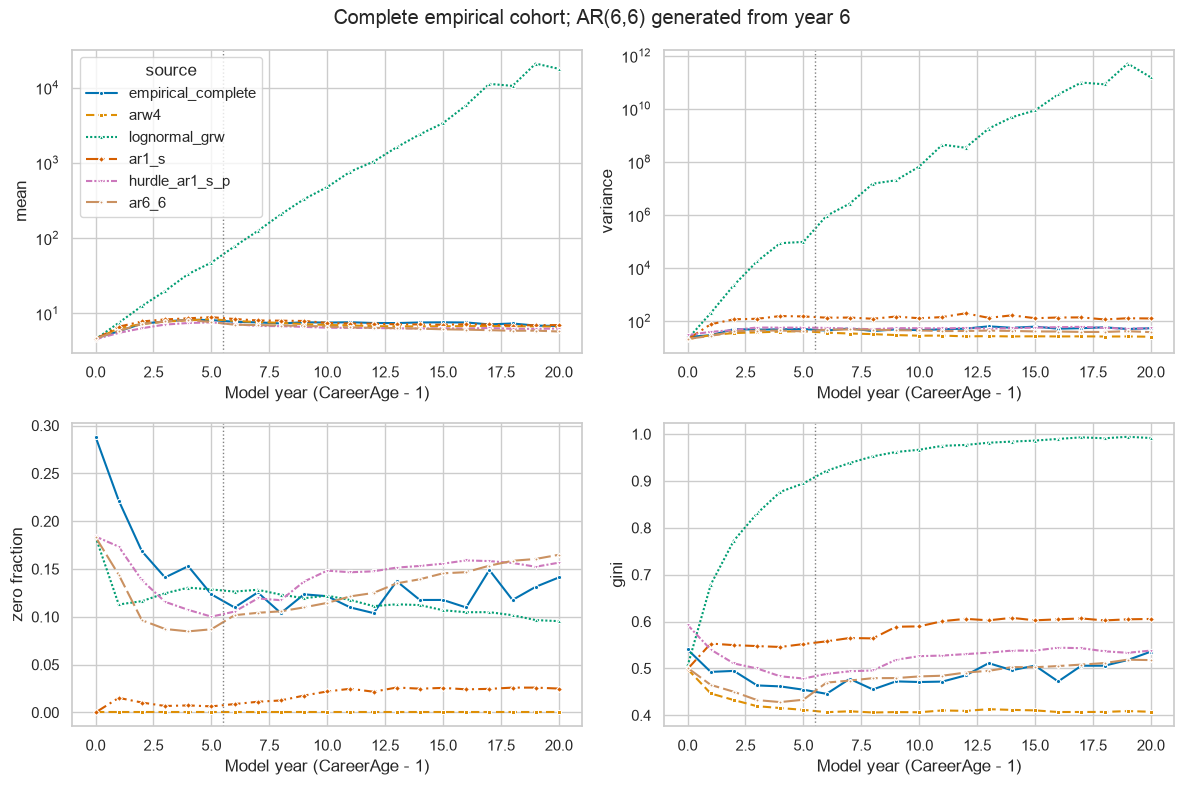

In [5]:
fig,axes = plt.subplots(2,2,figsize=(12,8))
subset = moments.loc[moments.source.isin(ORDER)]
for ax,metric in zip(axes.flat,['mean','variance','zero_fraction','gini']):
    lines(subset,'age',metric,ax)
    ax.set(xlabel='Model year (CareerAge - 1)',ylabel=metric.replace('_',' '))
    ax.axvline(5.5,color='.5',linestyle=':',linewidth=1)
    if metric in ['mean','variance']: ax.set_yscale('log')
    if ax!=axes.flat[0]: ax.get_legend().remove()
fig.suptitle('Complete empirical cohort; AR(6,6) generated from year 6')
save(fig,'annual_moments')

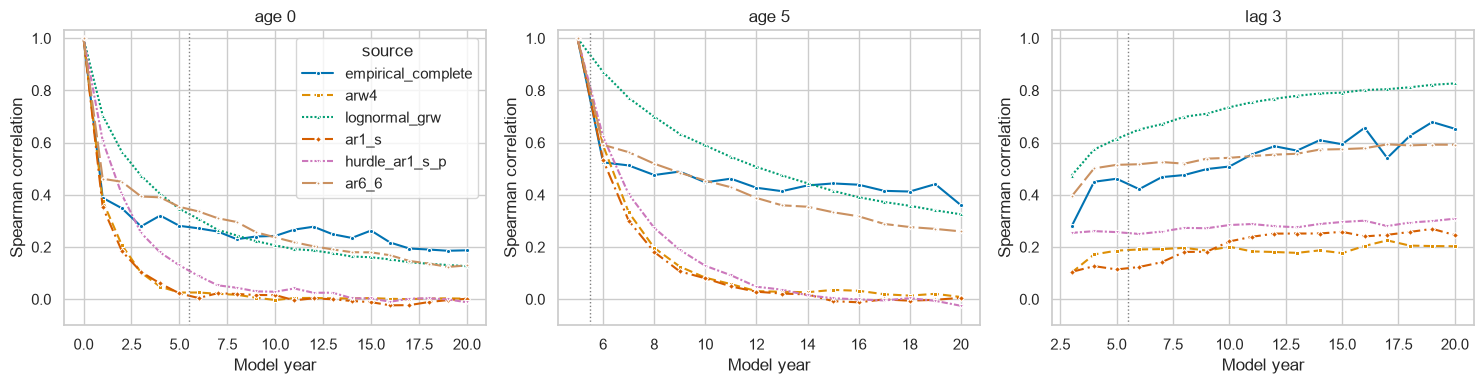

In [6]:
fig,axes = plt.subplots(1,3,figsize=(15,4))
for ax,reference in zip(axes,['age_0','age_5','lag_3']):
    subset = ranks.loc[ranks.measure.eq('annual') & ranks.reference.eq(reference)]
    lines(subset,'age','rho',ax)
    ax.axvline(5.5,color='.5',linestyle=':',linewidth=1)
    ax.set(title=reference.replace('_',' '),ylabel='Spearman correlation',xlabel='Model year',ylim=(-.1,1.03))
    if ax!=axes[0]: ax.get_legend().remove()
save(fig,'annual_rank_persistence')

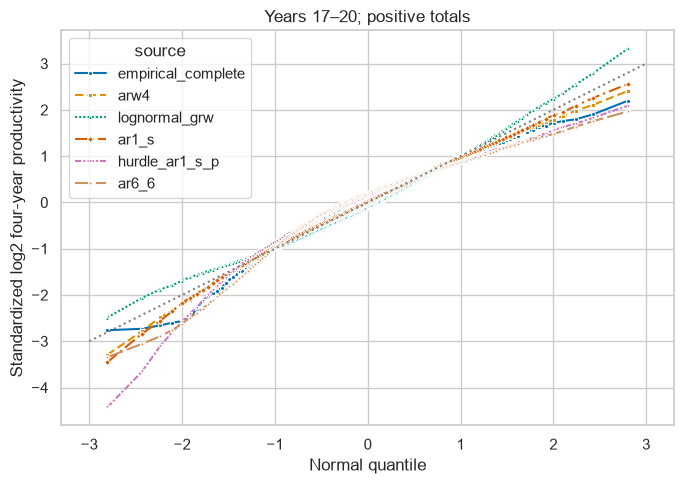

In [7]:
fig,ax = plt.subplots(figsize=(7,5))
lines(qq.loc[qq.window.eq('last_four')],'normal_quantile','observed_quantile',ax)
ax.plot([-3,3],[-3,3],color='.5',linestyle=':',label='Normal reference')
ax.set(xlabel='Normal quantile',ylabel='Standardized log2 four-year productivity',title='Years 17–20; positive totals')
save(fig,'last_four_qq')

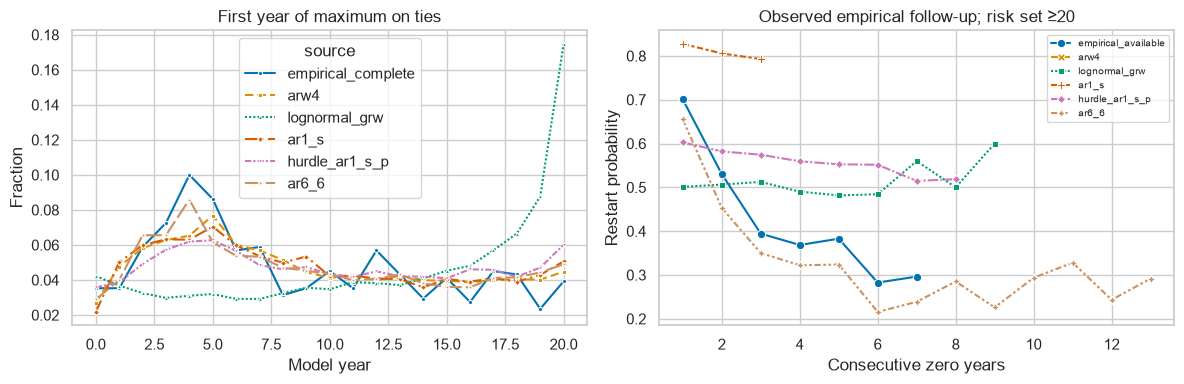

In [8]:
fig,axes = plt.subplots(1,2,figsize=(12,4))
lines(maximum,'age','fraction',axes[0])
axes[0].set(xlabel='Model year',ylabel='Fraction',title='First year of maximum on ties')
# available follow-up for empirical hazard; generated transitions for simulations
hazard_order = ['empirical_available'] + CONFIG['models']
hazard_palette = dict(zip(hazard_order,sns.color_palette('colorblind',len(hazard_order))))
sns.lineplot(data=hazard.loc[hazard.n_at_risk.ge(20)],x='duration',y='restart_probability',
             hue='source',style='source',hue_order=hazard_order,style_order=hazard_order,
             palette=hazard_palette,markers=True,dashes=True,ax=axes[1])
axes[1].set(xlabel='Consecutive zero years',ylabel='Restart probability',title='Observed empirical follow-up; risk set ≥20')
axes[1].legend(fontsize=7)
save(fig,'maximum_and_restart')

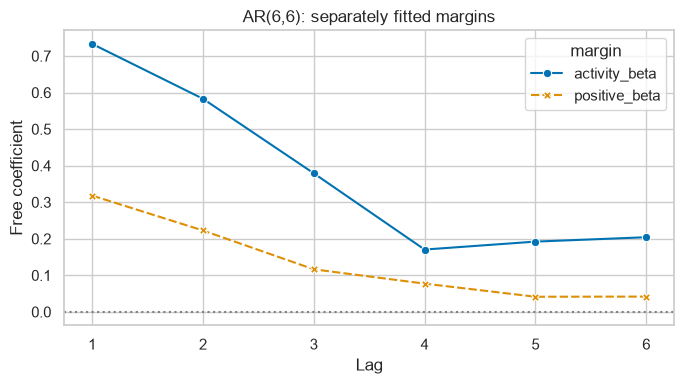

In [9]:
profiles = params.melt(id_vars='lag',value_vars=['activity_beta','positive_beta'],var_name='margin',value_name='coefficient')
fig,ax = plt.subplots(figsize=(7,4))
sns.lineplot(data=profiles,x='lag',y='coefficient',hue='margin',style='margin',markers=True,dashes=True,palette='colorblind',ax=ax)
ax.axhline(0,color='.5',linestyle=':')
ax.set(xlabel='Lag',ylabel='Free coefficient',title='AR(6,6): separately fitted margins')
save(fig,'ar6_6_coefficients')